# Naive Bayes Baseline Model

This notebook implements Naive Bayes baseline classifiers using TF-IDF
features from cleaned CFPB consumer complaint narratives. The goal is to
predict the financial product category associated with each complaint.

- **Section A** re-runs the team's original configuration (5,000 unigram
  TF-IDF features + Multinomial Naive Bayes) as a reference point.
- **Section B** uses the shared TF-IDF features from the project brief
  (unigrams + bigrams, 100k features) and tunes the smoothing parameter
  `alpha` for both **Multinomial** and **Complement** Naive Bayes.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import ComplementNB, MultinomialNB

In [2]:
RANDOM_STATE = 42

data_path = Path("../../data/processed/complaint_router_modeling_data.csv")
figures_dir = Path("../../figures")
metrics_dir = Path("../../results/metrics")

figures_dir.mkdir(parents=True, exist_ok=True)
metrics_dir.mkdir(parents=True, exist_ok=True)

short_labels = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt/Credit Mgmt",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan"
}

In [3]:
# Only the label, model input, and split columns are needed (keeps memory low)
df = pd.read_csv(data_path, usecols=["Product", "clean_narrative", "split"])

print("Dataset shape:", df.shape)
print("Number of classes:", df["Product"].nunique())
print("Missing clean narratives:", df["clean_narrative"].isna().sum())

Dataset shape: (162500, 3)
Number of classes: 11
Missing clean narratives: 0


### Train-Test Split

The dataset already contains a fixed `split` column (80% train / 20% test,
stratified on Product, seed 42) created in `01_data_cleaning.ipynb`. Using
this column instead of a new `train_test_split` guarantees that every model
in the project is evaluated on exactly the same test complaints. The test
set is only used for the final evaluation of each model.

In [4]:
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

X_train, y_train = train["clean_narrative"], train["Product"]
X_test, y_test = test["clean_narrative"], test["Product"]

print(f"Training samples: {len(X_train):,}")
print(f"Testing samples: {len(X_test):,}")
print("Number of classes:", y_train.nunique())

Training samples: 130,000
Testing samples: 32,500
Number of classes: 11


## A. Reference Configuration

This section reproduces the team's original setup: a TF-IDF vectorizer with
English stop words removed, 5,000 unigram features, and `min_df=5`, followed
by `MultinomialNB()` with default smoothing (`alpha=1.0`).

The team's earlier run on a previous sample of the data (with its own
random split) reached **accuracy 0.729 / macro-F1 0.69**. Re-running it on
the rebuilt dataset shows how comparable the new data is and gives a
reference point for the tuned models below.

In [5]:
reference_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=5
)

X_train_reference = reference_vectorizer.fit_transform(X_train)
X_test_reference = reference_vectorizer.transform(X_test)

reference_model = MultinomialNB()
reference_model.fit(X_train_reference, y_train)

reference_pred = reference_model.predict(X_test_reference)

reference_accuracy = accuracy_score(y_test, reference_pred)
reference_macro_f1 = f1_score(y_test, reference_pred, average="macro")
reference_weighted_f1 = f1_score(y_test, reference_pred, average="weighted")

print("Training TF-IDF shape:", X_train_reference.shape)
print(f"Test Accuracy: {reference_accuracy:.4f}  (earlier team run: 0.729)")
print(f"Test Macro-F1: {reference_macro_f1:.4f}  (earlier team run: 0.69)")
print(f"Test Weighted-F1: {reference_weighted_f1:.4f}")

Training TF-IDF shape: (130000, 5000)
Test Accuracy: 0.7278  (earlier team run: 0.729)
Test Macro-F1: 0.6953  (earlier team run: 0.69)
Test Weighted-F1: 0.7226


In [6]:
# The reference features are no longer needed
del X_train_reference, X_test_reference, reference_vectorizer

### Reference Findings

On the rebuilt dataset the original configuration reaches accuracy
**0.728** and macro-F1 **0.695**, essentially the same as the team's earlier
run (0.729 / 0.69). The rebuilt data (new cleaning, de-duplication, and the
shared fixed split) leaves the difficulty of the task unchanged, so the
results below can be compared directly with the team's original result.

## B. Tuned Naive Bayes with the Shared TF-IDF Features

### TF-IDF Feature Extraction

All product models in the project use the same TF-IDF configuration:
unigrams and bigrams, English stop words removed, terms that appear in at
least 5 narratives and in at most 90% of them, sublinear term frequency
(`1 + log(tf)`), and the 100,000 most frequent terms. The vectorizer is
fitted only on the training data to prevent information from the test set
from leaking into the model.

In [7]:
FEATURES_DESCRIPTION = "TF-IDF 1-2 grams (100k)"

vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    sublinear_tf=True,
    max_features=100_000
)

start = time.perf_counter()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
vectorizer_seconds = time.perf_counter() - start

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print(f"Vectorizing time: {vectorizer_seconds:.1f} s")

Training TF-IDF shape: (130000, 100000)
Testing TF-IDF shape: (32500, 100000)
Vectorizing time: 52.9 s


### Hyperparameter Tuning

The smoothing parameter `alpha` adds a pseudo-count to every term so that
words never seen in a class do not get zero probability. Smaller values
trust the observed counts more; larger values smooth more strongly. With
100,000 features, the default `alpha=1.0` can over-smooth.

Two Naive Bayes variants are tuned:

- **MultinomialNB** estimates term probabilities from the documents *in*
  each class.
- **ComplementNB** estimates them from the documents *not in* each class
  (its complement). Each complement contains much more data than a small
  class on its own, which makes the estimates more stable and usually helps
  on imbalanced text datasets like this one.

Each `alpha` is scored with 3-fold stratified cross-validation on the
training set using macro-F1. The test set is not used for tuning.

In [8]:
ALPHAS = [0.01, 0.03, 0.1, 0.3, 1.0]

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Note: the TF-IDF vocabulary/IDF weights were fitted on the full training set
# before cross-validation. This leaks a negligible amount of information into
# the validation folds and does not affect the held-out test set.


def cv_results_table(search):
    results = pd.DataFrame(search.cv_results_)
    table = results[["param_alpha", "mean_test_score", "std_test_score", "rank_test_score"]]
    table.columns = ["alpha", "CV Macro-F1 (mean)", "CV Macro-F1 (std)", "Rank"]
    return table.round(4).set_index("alpha")


# Naive Bayes fits in about a second, so folds run sequentially to save memory
mnb_search = GridSearchCV(
    MultinomialNB(),
    param_grid={"alpha": ALPHAS},
    scoring="f1_macro",
    cv=cv,
    n_jobs=1
)

mnb_search.fit(X_train_tfidf, y_train)

print("Best MultinomialNB params:", mnb_search.best_params_)
print(f"Best CV Macro-F1: {mnb_search.best_score_:.4f}")

cv_results_table(mnb_search)

Best MultinomialNB params: {'alpha': 0.03}
Best CV Macro-F1: 0.7190


,CV Macro-F1 (mean),CV Macro-F1 (std),Rank
alpha,,,
0.01,0.7136,0.0019,3
0.03,0.7190,0.0018,1
0.10,0.7183,0.0011,2
0.30,0.6925,0.0018,4
1.00,0.6065,0.0017,5


In [9]:
cnb_search = GridSearchCV(
    ComplementNB(),
    param_grid={"alpha": ALPHAS},
    scoring="f1_macro",
    cv=cv,
    n_jobs=1
)

cnb_search.fit(X_train_tfidf, y_train)

print("Best ComplementNB params:", cnb_search.best_params_)
print(f"Best CV Macro-F1: {cnb_search.best_score_:.4f}")

cv_results_table(cnb_search)

Best ComplementNB params: {'alpha': 0.01}
Best CV Macro-F1: 0.7210


,CV Macro-F1 (mean),CV Macro-F1 (std),Rank
alpha,,,
0.01,0.7210,0.0011,1
0.03,0.7205,0.0012,3
0.10,0.7206,0.0013,2
0.30,0.7197,0.0009,4
1.00,0.7163,0.0011,5


### Final Fit and Test Evaluation

Each model is refit on the full training set with its best `alpha` (the
fit time is recorded) and then evaluated once on the held-out test set.

In [10]:
def fit_and_predict(model):
    start = time.perf_counter()
    model.fit(X_train_tfidf, y_train)
    train_seconds = time.perf_counter() - start
    return model.predict(X_test_tfidf), train_seconds


mnb_model = MultinomialNB(**mnb_search.best_params_)
mnb_pred, mnb_train_seconds = fit_and_predict(mnb_model)

cnb_model = ComplementNB(**cnb_search.best_params_)
cnb_pred, cnb_train_seconds = fit_and_predict(cnb_model)

for name, y_pred, seconds in [
    ("MultinomialNB", mnb_pred, mnb_train_seconds),
    ("ComplementNB", cnb_pred, cnb_train_seconds),
]:
    print(name)
    print(f"  Test Accuracy:    {accuracy_score(y_test, y_pred):.4f}")
    print(f"  Test Macro-F1:    {f1_score(y_test, y_pred, average='macro'):.4f}")
    print(f"  Test Weighted-F1: {f1_score(y_test, y_pred, average='weighted'):.4f}")
    print(f"  Train time:       {seconds:.2f} s")

MultinomialNB
  Test Accuracy:    0.7494
  Test Macro-F1:    0.7230


  Test Weighted-F1: 0.7463
  Train time:       0.46 s
ComplementNB
  Test Accuracy:    0.7586
  Test Macro-F1:    0.7211


  Test Weighted-F1: 0.7514
  Train time:       0.49 s


### Multinomial Naive Bayes — Classification Report

In [11]:
print(classification_report(y_test, mnb_pred, digits=3))

                                                         precision    recall  f1-score   support

                            Checking or savings account      0.617     0.867     0.721      4000
                                            Credit card      0.672     0.763     0.715      4000
    Credit reporting or other personal consumer reports      0.795     0.823     0.808      7000
                                        Debt collection      0.760     0.701     0.729      5000
                              Debt or credit management      0.623     0.361     0.457      1000
     Money transfer, virtual currency, or money service      0.898     0.560     0.690      3000
                                               Mortgage      0.842     0.916     0.878      2000
Payday loan, title loan, personal loan, or advance loan      0.654     0.559     0.603      1500
                                           Prepaid card      0.779     0.612     0.685      1000
                             

### Complement Naive Bayes — Classification Report

In [12]:
print(classification_report(y_test, cnb_pred, digits=3))

                                                         precision    recall  f1-score   support

                            Checking or savings account      0.616     0.873     0.722      4000
                                            Credit card      0.737     0.722     0.730      4000
    Credit reporting or other personal consumer reports      0.752     0.871     0.807      7000
                                        Debt collection      0.790     0.697     0.740      5000
                              Debt or credit management      0.878     0.288     0.434      1000
     Money transfer, virtual currency, or money service      0.828     0.689     0.752      3000
                                               Mortgage      0.828     0.931     0.877      2000
Payday loan, title loan, personal loan, or advance loan      0.798     0.413     0.545      1500
                                           Prepaid card      0.902     0.513     0.654      1000
                             

### Confusion Matrices

The confusion matrices are row-normalized: each row shows how the
complaints of one actual product were distributed across the predicted
products, so the diagonal equals each class's recall.

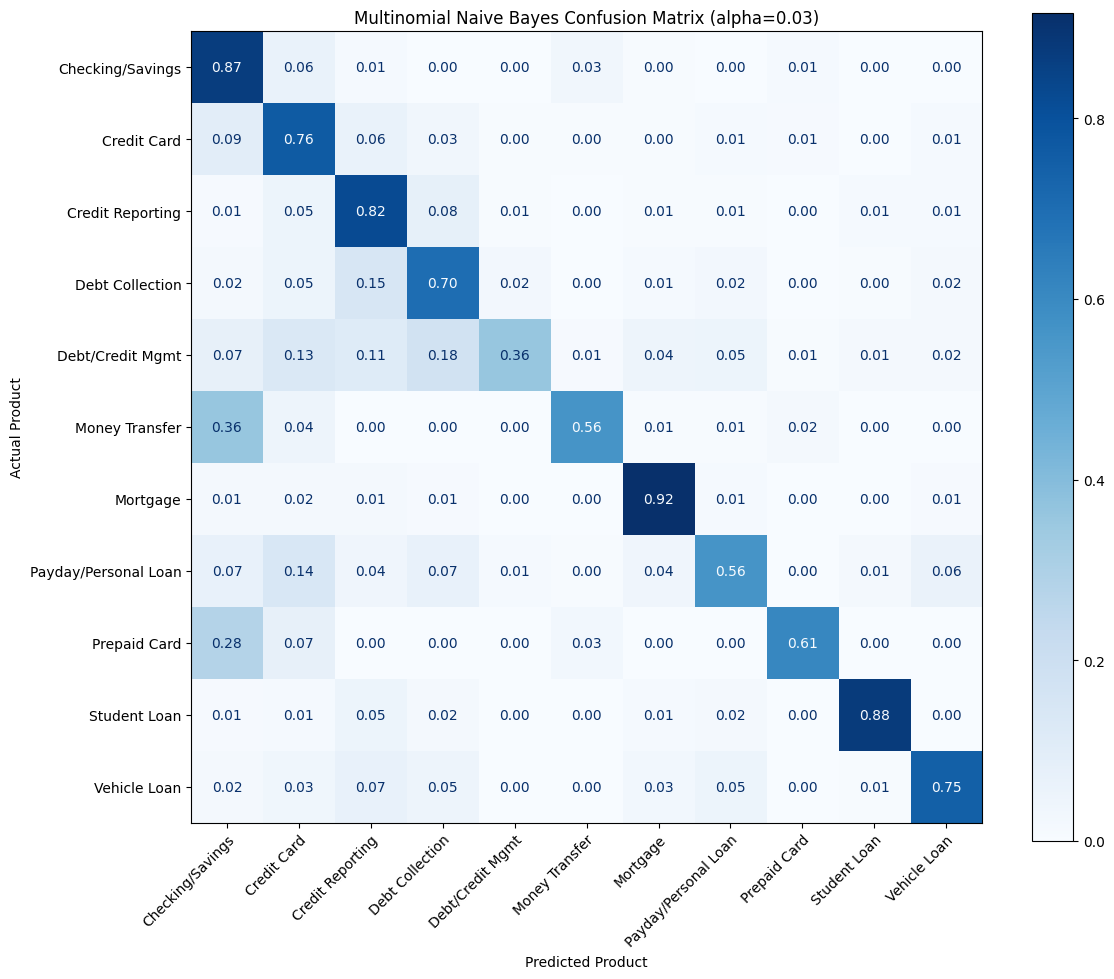

In [13]:
def plot_confusion_matrix(y_pred, labels, title, output_path):
    display_labels = [short_labels[label] for label in labels]

    fig, ax = plt.subplots(figsize=(12, 10))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=labels,
        display_labels=display_labels,
        normalize="true",
        values_format=".2f",
        xticks_rotation=45,
        cmap="Blues",
        ax=ax
    )

    plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
    ax.set_title(title)
    ax.set_xlabel("Predicted Product")
    ax.set_ylabel("Actual Product")

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


plot_confusion_matrix(
    mnb_pred,
    mnb_model.classes_,
    f"Multinomial Naive Bayes Confusion Matrix (alpha={mnb_model.alpha})",
    figures_dir / "naive_bayes_confusion_matrix.png"
)

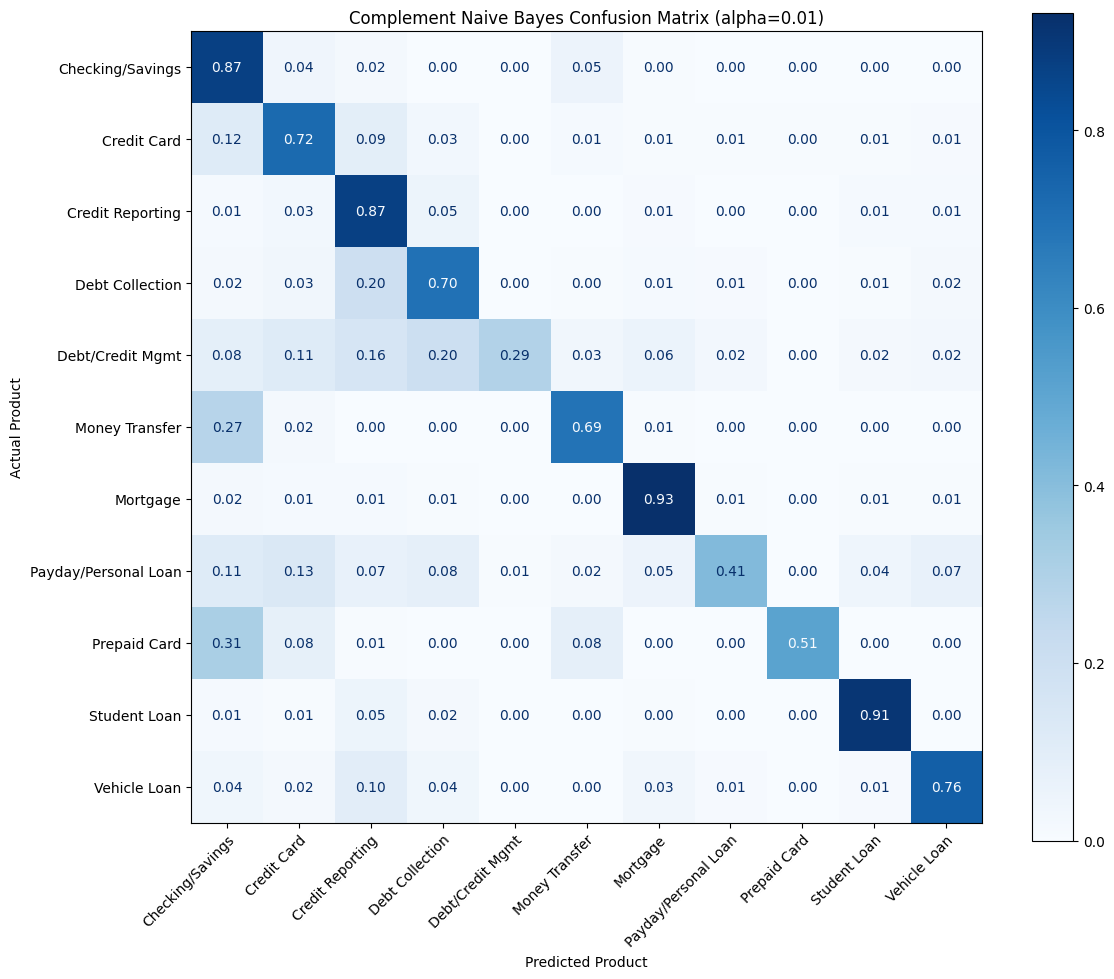

In [14]:
plot_confusion_matrix(
    cnb_pred,
    cnb_model.classes_,
    f"Complement Naive Bayes Confusion Matrix (alpha={cnb_model.alpha})",
    figures_dir / "complement_nb_confusion_matrix.png"
)

### Save Metrics

The test metrics are saved as JSON files in `results/metrics/` so that
`model_comparison.ipynb` can compare every model in the project.

In [15]:
def build_metrics(model_key, display_name, search, y_pred, train_seconds):
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

    per_class = {
        product: {
            "precision": float(report[product]["precision"]),
            "recall": float(report[product]["recall"]),
            "f1": float(report[product]["f1-score"]),
            "support": int(report[product]["support"]),
        }
        for product in sorted(short_labels)
    }

    return {
        "model": model_key,
        "display_name": display_name,
        "task": "product",
        "features": FEATURES_DESCRIPTION,
        "best_params": {key: float(value) for key, value in search.best_params_.items()},
        "cv_macro_f1": float(search.best_score_),
        "test_accuracy": float(accuracy_score(y_test, y_pred)),
        "test_macro_f1": float(f1_score(y_test, y_pred, average="macro")),
        "test_weighted_f1": float(f1_score(y_test, y_pred, average="weighted")),
        "per_class": per_class,
        "train_seconds": float(train_seconds),
        "n_train": int(len(y_train)),
        "n_test": int(len(y_test)),
    }


all_metrics = [
    build_metrics("naive_bayes", "Multinomial Naive Bayes", mnb_search, mnb_pred, mnb_train_seconds),
    build_metrics("complement_nb", "Complement Naive Bayes", cnb_search, cnb_pred, cnb_train_seconds),
]

for metrics in all_metrics:
    output_path = metrics_dir / f"{metrics['model']}.json"

    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)

    print(f"Saved {output_path}")

Saved ..\..\results\metrics\naive_bayes.json
Saved ..\..\results\metrics\complement_nb.json


### Comparison of Naive Bayes Configurations

In [16]:
nb_comparison = pd.DataFrame([
    {
        "Configuration": "Reference: MultinomialNB, 5k unigrams",
        "alpha": 1.0,
        "CV Macro-F1": np.nan,
        "Test Accuracy": reference_accuracy,
        "Test Macro-F1": reference_macro_f1,
        "Test Weighted-F1": reference_weighted_f1,
    },
    *[
        {
            "Configuration": f"{m['display_name']}, shared TF-IDF (tuned)",
            "alpha": m["best_params"]["alpha"],
            "CV Macro-F1": m["cv_macro_f1"],
            "Test Accuracy": m["test_accuracy"],
            "Test Macro-F1": m["test_macro_f1"],
            "Test Weighted-F1": m["test_weighted_f1"],
        }
        for m in all_metrics
    ],
]).set_index("Configuration")

nb_comparison.round(4)

,alpha,CV Macro-F1,Test Accuracy,Test Macro-F1,Test Weighted-F1
Configuration,,,,,
"Reference: MultinomialNB, 5k unigrams",1.00,NaN,0.7278,0.6953,0.7226
"Multinomial Naive Bayes, shared TF-IDF (tuned)",0.03,0.719,0.7494,0.7230,0.7463
"Complement Naive Bayes, shared TF-IDF (tuned)",0.01,0.721,0.7586,0.7211,0.7514


## Naive Bayes Results Summary

The original configuration (5,000 unigrams, `alpha=1.0`) reached a test
accuracy of **0.728** and macro-F1 of **0.695** on the rebuilt dataset,
matching the team's earlier run (0.729 / 0.69).

The shared TF-IDF features (unigrams + bigrams, 100k features, sublinear
TF) with tuned smoothing improved both variants:

| Model | alpha | CV Macro-F1 | Test Accuracy | Test Macro-F1 | Test Weighted-F1 |
|---|---|---|---|---|---|
| Reference MultinomialNB (5k unigrams) | 1.0 | – | 0.728 | 0.695 | 0.723 |
| **MultinomialNB** (shared TF-IDF) | 0.03 | 0.719 | 0.749 | **0.723** | 0.746 |
| **ComplementNB** (shared TF-IDF) | 0.01 | 0.721 | 0.759 | **0.721** | 0.751 |

- **Smoothing matters for MultinomialNB.** Its CV macro-F1 falls from 0.719
  at `alpha=0.03` to 0.607 at the default `alpha=1.0`. TF-IDF weights are
  small fractions, so adding a pseudo-count of 1 to each of 100,000
  features outweighs the real evidence for the smaller classes.
  ComplementNB is far less sensitive (CV 0.716–0.721 across the grid).
- **The two tuned models are essentially tied on macro-F1** (0.723 vs.
  0.721), about **+0.03** over the reference configuration. ComplementNB
  has higher accuracy, weighted-F1, and precision. MultinomialNB recovers
  more of the small classes, for example recall on Debt/Credit Mgmt (0.36
  vs. 0.29), Payday/Personal Loan (0.56 vs. 0.41), and Prepaid Card (0.61
  vs. 0.51).

Performance varied across product categories. **Student Loan** (F1 0.90 /
0.89), **Mortgage** (0.88), and **Credit Reporting** (0.81) were classified
most accurately. **Debt or Credit Management** (F1 0.46 / 0.43) and
**Payday/Personal Loan** (0.60 / 0.54) remained the most difficult.

The confusion matrices show that categories with similar financial
terminology are still frequently confused:

- Many **Money Transfer** (36% for MultinomialNB, 27% for ComplementNB) and
  **Prepaid Card** (28% / 31%) complaints are predicted as
  **Checking/Savings**, which lowers Checking/Savings precision to about
  0.62.
- **Debt Collection** complaints are often predicted as **Credit
  Reporting** (15% / 20%).
- **Debt/Credit Mgmt** complaints are spread across Debt Collection, Credit
  Reporting, and Credit Card.

Overall, Naive Bayes provides a fast baseline: each final model trains in
about **0.5 seconds** on 130,000 complaints (building the TF-IDF features
takes about a minute). These results are compared with Logistic Regression,
Linear SVM, and the other models in `model_comparison.ipynb`.